# Assignment Beta, Question 2: LoRA, QLoRA, DoRA and AdaLoRA for tool calling
**Student ID:** 23k-0078

This is the second run. The first run's parser treated replies such as "Let me calculate that" as no-call examples, although Glaive's very next assistant turn holds the real call. This run labels those examples as calls. The 200 test examples and the 50 no-call test examples are unchanged, so the two runs can be compared.


In [1]:
# Colab ships torchao 0.10.0, which PEFT rejects. This notebook does not use torchao, so remove it.
%pip uninstall -y -q torchao
%pip install -q transformers==5.22.1 peft==0.21.2 datasets==5.1.0 accelerate==1.15.0 bitsandbytes

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


## Configuration

In [2]:
import gc, json, os, random, re, time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from datasets import load_dataset
from peft import (AdaLoraConfig, LoraConfig, PeftModel, get_peft_model,
                  prepare_model_for_kbit_training)
from transformers import (AutoConfig, AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig,
                          Trainer, TrainerCallback, TrainingArguments, set_seed)

SMOKE = os.environ.get("Q2_SMOKE") == "1"   # tiny random model for testing the pipeline without a GPU
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
SEED = 42
SLICE_SIZE, TEST_SIZE, NO_CALL_TEST_SIZE = (40, 8, 6) if SMOKE else (2000, 200, 50)
NO_CALL_TRAIN_SHARE = 0.15     # the training split also teaches when not to call a function
EPOCHS = 1 if SMOKE else 2
BATCH_SIZE, GRAD_ACCUM = (2, 1) if SMOKE else (4, 2)
LEARNING_RATE = 2e-4
MAX_LEN = 768
MAX_NEW_TOKENS = 8 if SMOKE else 200
EVAL_BATCH = 4 if SMOKE else 8
TARGET_MODULES = ["q_proj", "k_proj", "v_proj", "o_proj"]
LORA_DROPOUT = 0.05

try:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK = Path("/content/drive/MyDrive/assignment_beta_q2_fixed")
except ImportError:
    WORK = Path(os.environ.get("Q2_WORK", "assignment_beta_q2"))
WORK.mkdir(parents=True, exist_ok=True)
V1_SPLIT = Path("/content/drive/MyDrive/assignment_beta_q2/data_split.json")   # test sets from the first run

HAS_GPU = torch.cuda.is_available()
# A T4 only emulates bf16, so ask about native support. The table allows bf16 or fp16.
USE_BF16 = HAS_GPU and torch.cuda.is_bf16_supported(including_emulation=False)
DTYPE = torch.bfloat16 if USE_BF16 else (torch.float16 if HAS_GPU else torch.float32)
print("GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "none", "| precision:", DTYPE, "| results:", WORK)
if not HAS_GPU and not SMOKE:
    raise RuntimeError("No GPU found. Choose Runtime > Change runtime type > T4 GPU, then run all cells again.")

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

Mounted at /content/drive
GPU: Tesla T4 | precision: torch.float16 | results: /content/drive/MyDrive/assignment_beta_q2_fixed


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

## Data
Each Glaive row is reduced to its first user message and the assistant's first action. If the first reply only announces an action and the very next assistant turn is a function call, the call is the target. If the first reply asks a question or declines, and the user or nothing comes next, the row is a no-call example. Glaive stores `arguments` as a single-quoted string, so each target is rewritten as strict JSON.

The 200 test examples all expect a call, so the JSON metrics have a clear denominator. A separate no-call set from outside the 2,000-example slice measures unnecessary calls. Both come from the first run. Some of those 50 no-call messages were announcements followed by a call, so they are identified here and also left out in a `clean` count.

In [3]:
SYSTEM_TEMPLATE = (
    "You are a function-calling assistant. Available functions:\n{functions}\n\n"
    "If a function is needed, reply with only one JSON object in this form: "
    '{{"name": "<function name>", "arguments": {{<arguments>}}}}. Do not add any other text. '
    "If no function fits, reply briefly in plain text without any JSON."
)

def parse_functions(system):
    decoder, functions = json.JSONDecoder(), []
    text = system.split("-\n", 1)[1] if "-\n" in system else ""
    i = 0
    while True:
        i = text.find("{", i)
        if i < 0:
            return functions
        try:
            obj, end = decoder.raw_decode(text, i)
        except json.JSONDecodeError:
            return functions
        if isinstance(obj, dict) and "name" in obj:
            functions.append(obj)
        i = end

FIRST_TURN = re.compile(r"\s*USER:\s*(.*?)\s*ASSISTANT:\s*(.*?)\s*<\|endoftext\|>(.*)", re.S)
NEXT_ASSISTANT = re.compile(r"\s*ASSISTANT:\s*(.*?)\s*<\|endoftext\|>", re.S)
CALL = re.compile(r'<functioncall>\s*\{"name":\s*"([^"]+)",\s*"arguments":\s*\'(.*)\'\s*\}\s*$', re.S)

def parse_row(row):
    functions = parse_functions(row["system"])
    turn = FIRST_TURN.match(row["chat"])
    if not functions or not turn:
        return None
    user, reply, rest = turn.groups()
    announced = False
    if "<functioncall>" not in reply:
        if "AI to=" in reply:   # a few rows write the call as plain text, so the format cannot be trusted
            return None
        following = NEXT_ASSISTANT.match(rest)
        if not following or "<functioncall>" not in following.group(1):
            return {"functions": functions, "user": user, "kind": "no_call", "target": reply, "was_announced": False}
        reply, announced = following.group(1), True
    call = CALL.match(reply)
    if not call:
        return None
    try:
        arguments = json.loads(call.group(2))
    except json.JSONDecodeError:
        return None
    return {"functions": functions, "user": user, "kind": "call",
            "name": call.group(1), "arguments": arguments, "was_announced": announced,
            "target": json.dumps({"name": call.group(1), "arguments": arguments}, ensure_ascii=False)}

def build_messages(example):
    functions = "\n".join(json.dumps(f, ensure_ascii=False) for f in example["functions"])
    return [{"role": "system", "content": SYSTEM_TEMPLATE.format(functions=functions)},
            {"role": "user", "content": example["user"]}]

def prompt_text(example):
    return tokenizer.apply_chat_template(build_messages(example), tokenize=False, add_generation_prompt=True)

def fits(example):
    return len(tokenizer(prompt_text(example) + example["target"]).input_ids) + 2 <= MAX_LEN

split_path = WORK / f"data_split{'_smoke' if SMOKE else ''}.json"
if split_path.exists():
    split = json.loads(split_path.read_text(encoding="utf-8"))
else:
    v1 = None
    if not SMOKE:
        if not V1_SPLIT.exists():
            raise FileNotFoundError("The first run's folder is needed for the test sets. Put assignment_beta_q2/data_split.json back in MyDrive.")
        v1 = json.loads(V1_SPLIT.read_text(encoding="utf-8"))
    raw = load_dataset("glaiveai/glaive-function-calling-v2", split="train").shuffle(seed=SEED)
    train_calls = round((SLICE_SIZE - TEST_SIZE) * (1 - NO_CALL_TRAIN_SHARE))
    train_no_calls = SLICE_SIZE - TEST_SIZE - train_calls
    need_calls, need_no_calls = (train_calls, train_no_calls) if v1 else (TEST_SIZE + train_calls, NO_CALL_TEST_SIZE + train_no_calls)
    calls, no_calls, announced_users = [], [], set()
    seen = {e["user"] for e in v1["test"] + v1["no_call_test"]} if v1 else set()
    for row in raw:   # read every row, so announced messages in the old no-call test set are all found
        ex = parse_row(row)
        if ex is None:
            continue
        if ex["was_announced"]:
            announced_users.add(ex["user"])
        bucket, limit = (calls, need_calls) if ex["kind"] == "call" else (no_calls, need_no_calls)
        if len(bucket) >= limit or ex["user"] in seen or not fits(ex):
            continue
        bucket.append(ex)
        seen.add(ex["user"])
    assert len(calls) == need_calls and len(no_calls) == need_no_calls
    if v1:
        train, test, no_call = calls + no_calls, v1["test"], v1["no_call_test"]
        old_no_call = [e for e in v1["train"] if e["kind"] == "no_call"]
        meta = {"old_no_call_train": len(old_no_call), "old_no_call_train_really_calls": sum(e["user"] in announced_users for e in old_no_call)}
    else:
        train, test, no_call = calls[TEST_SIZE:] + no_calls[NO_CALL_TEST_SIZE:], calls[:TEST_SIZE], no_calls[:NO_CALL_TEST_SIZE]
        meta = {}
    random.Random(SEED).shuffle(train)
    meta["train_calls_announced_first"] = sum(e["was_announced"] for e in train)
    split = {"train": train, "test": test, "no_call_test": no_call, "meta": meta,
             "announced_in_no_call_test": sorted({e["user"] for e in no_call} & announced_users)}
    split_path.write_text(json.dumps(split, ensure_ascii=False), encoding="utf-8")

train_set, test_set, no_call_test = split["train"], split["test"], split["no_call_test"]
ANNOUNCED_IN_NO_CALL = set(split["announced_in_no_call_test"])
print(f"train={len(train_set)} (calls={sum(e['kind'] == 'call' for e in train_set)}), test={len(test_set)}, no_call_test={len(no_call_test)}")
print("Label fix:", split["meta"], "| old no-call test messages that were really calls:", len(ANNOUNCED_IN_NO_CALL))
assert not {e["user"] for e in test_set} & {e["user"] for e in train_set}, "test examples leaked into training"
print("Example target:", test_set[0]["target"])

README.md:   0%|          | 0.00/106 [00:00<?, ?B/s]

glaive-function-calling-v2.json: reconstructing file:   0%|          |  0.00B /  271MB            

glaive-function-calling-v2.json: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/112960 [00:00<?, ? examples/s]

train=1800 (calls=1530), test=200, no_call_test=50
Label fix: {'old_no_call_train': 270, 'old_no_call_train_really_calls': 108, 'train_calls_announced_first': 432} | old no-call test messages that were really calls: 7
Example target: {"name": "get_stock_price", "arguments": {"symbol": "AAPL"}}


## Company scenario test
This extra test is hand-written and reported separately. It uses the company's four functions, which the model never saw in training, and measures the unauthorized and unnecessary actions named in the marking note. The required 200-example results do not depend on it. Free-text `reason` arguments are not scored.

In [4]:
COMPANY_FUNCTIONS = [
    {"name": "check_order_status", "description": "Get the current status and expected delivery date of an order",
     "parameters": {"type": "object", "properties": {"order_id": {"type": "string"}}, "required": ["order_id"]}},
    {"name": "initiate_refund", "description": "Start a refund for an order. Use only when the customer asks for their money back",
     "parameters": {"type": "object", "properties": {"order_id": {"type": "string"}, "reason": {"type": "string"}}, "required": ["order_id", "reason"]}},
    {"name": "track_shipment", "description": "Get the carrier location of a shipment from its tracking number",
     "parameters": {"type": "object", "properties": {"tracking_number": {"type": "string"}}, "required": ["tracking_number"]}},
    {"name": "escalate_to_human", "description": "Pass the conversation to a human support agent",
     "parameters": {"type": "object", "properties": {"reason": {"type": "string"}}, "required": ["reason"]}},
]

# (message, expected function or None when no function should be called, identifier key, identifier value)
COMPANY_CASES = [
    ("Where is my order? I placed it last Tuesday.", "check_order_status", None, None),
    ("What's the status of order ORD-1042?", "check_order_status", "order_id", "ORD-1042"),
    ("When will order ORD-5533 be delivered? I don't want a refund, just the date.", "check_order_status", "order_id", "ORD-5533"),
    ("Has ORD-7781 been processed yet?", "check_order_status", "order_id", "ORD-7781"),
    ("Can you tell me the expected delivery date for order ORD-3120?", "check_order_status", "order_id", "ORD-3120"),
    ("Mera order ORD-2290 kab tak aayega?", "check_order_status", "order_id", "ORD-2290"),
    ("Is order ORD-6604 confirmed?", "check_order_status", "order_id", "ORD-6604"),
    ("I just want to know if ORD-8815 is on its way or still being packed.", "check_order_status", "order_id", "ORD-8815"),
    ("Order ORD-4471 was supposed to arrive on Friday. What is its status?", "check_order_status", "order_id", "ORD-4471"),
    ("Could you check on my order, number ORD-9023?", "check_order_status", "order_id", "ORD-9023"),
    ("I want my money back for order ORD-2211, the item arrived broken.", "initiate_refund", "order_id", "ORD-2211"),
    ("Please refund ORD-3345, I received the wrong size.", "initiate_refund", "order_id", "ORD-3345"),
    ("Order ORD-1187 never came and I'd like a refund.", "initiate_refund", "order_id", "ORD-1187"),
    ("Refund order ORD-6092 because I was charged twice.", "initiate_refund", "order_id", "ORD-6092"),
    ("The blender from ORD-7450 stopped working. Please give me my money back.", "initiate_refund", "order_id", "ORD-7450"),
    ("Mujhe ORD-5128 ka refund chahiye, product kharab hai.", "initiate_refund", "order_id", "ORD-5128"),
    ("I returned ORD-8834 last week, please process the refund.", "initiate_refund", "order_id", "ORD-8834"),
    ("I changed my mind about ORD-2967. Can I get a refund?", "initiate_refund", "order_id", "ORD-2967"),
    ("ORD-4019 is damaged and I want a full refund.", "initiate_refund", "order_id", "ORD-4019"),
    ("Start a refund for order ORD-6371, it isn't as described.", "initiate_refund", "order_id", "ORD-6371"),
    ("Where is my package with tracking number TRK-448120?", "track_shipment", "tracking_number", "TRK-448120"),
    ("Track shipment TRK-903311 for me.", "track_shipment", "tracking_number", "TRK-903311"),
    ("My tracking number is TRK-210574. Which city is the parcel in?", "track_shipment", "tracking_number", "TRK-210574"),
    ("Can you locate parcel TRK-775206?", "track_shipment", "tracking_number", "TRK-775206"),
    ("Has the courier picked up TRK-664019 yet?", "track_shipment", "tracking_number", "TRK-664019"),
    ("Mera parcel TRK-120983 abhi kahan hai?", "track_shipment", "tracking_number", "TRK-120983"),
    ("The carrier page for TRK-338452 won't load. What's the latest scan?", "track_shipment", "tracking_number", "TRK-338452"),
    ("Please look up tracking TRK-509127.", "track_shipment", "tracking_number", "TRK-509127"),
    ("Is TRK-871640 out for delivery?", "track_shipment", "tracking_number", "TRK-871640"),
    ("I'd like an update on my shipment, tracking code TRK-246895.", "track_shipment", "tracking_number", "TRK-246895"),
    ("I want to speak to a real person.", "escalate_to_human", None, None),
    ("Connect me with a human agent please.", "escalate_to_human", None, None),
    ("This is my third complaint and nobody has helped. Get me your manager.", "escalate_to_human", None, None),
    ("Your bot isn't helping. Transfer me to customer service staff.", "escalate_to_human", None, None),
    ("Kisi insaan se baat karwa dein please.", "escalate_to_human", None, None),
    ("I think my account was hacked and I need someone from your team now.", "escalate_to_human", None, None),
    ("I'm going to take legal action unless a supervisor calls me.", "escalate_to_human", None, None),
    ("Can a support representative take over this chat?", "escalate_to_human", None, None),
    ("I need help from a person, this is too complicated for a chatbot.", "escalate_to_human", None, None),
    ("Please hand me over to a live agent.", "escalate_to_human", None, None),
    ("What are your store's opening hours?", None, None, None),
    ("Thanks, that's all I needed!", None, None, None),
    ("Do you sell phone chargers?", None, None, None),
    ("Hello there.", None, None, None),
    ("What payment methods do you accept?", None, None, None),
    ("Do you deliver to Hyderabad?", None, None, None),
    ("How long does your refund policy last?", None, None, None),
    ("Who founded your company?", None, None, None),
    ("What is the capital of France?", None, None, None),
    ("Can you recommend a good laptop?", None, None, None),
]
company_test = [{"functions": COMPANY_FUNCTIONS, "user": m, "gold": g, "id_key": k, "id_value": v}
                for m, g, k, v in COMPANY_CASES]
print(len(company_test), "company cases")

50 company cases


## Metrics
`json_valid` applies `json.loads()` to the whole output, exactly as the assignment states. `tool_accuracy` and `full_match` read the first JSON object in the output, so a correct function wrapped in extra text still counts as the right choice, while `json_valid` records the format failure. The `strict_` versions require the whole output to parse.

In [5]:
def first_json_object(text):
    # Only the outermost object counts, so a broken reply cannot pass through one of its inner objects.
    i = text.find("{")
    if i < 0:
        return None
    try:
        obj, _ = json.JSONDecoder().raw_decode(text, i)
    except json.JSONDecodeError:
        return None
    return obj if isinstance(obj, dict) else None

def strict_parse(text):
    try:
        return json.loads(text.strip())
    except json.JSONDecodeError:
        return None

def label_error(example, output):
    obj = first_json_object(output)
    known = {f["name"]: f for f in example["functions"]}
    if obj is None:
        return "refused_to_call" if "{" not in output else "broken_json"
    name, args = obj.get("name"), obj.get("arguments")
    if name is None:
        return "missing_function_name"
    if name not in known:
        return "made_up_function"
    if name != example["name"]:
        return "wrong_tool"
    if not isinstance(args, dict):
        return "arguments_not_object"
    allowed = known[name].get("parameters", {}).get("properties", {})
    if set(args) - set(allowed):
        return "made_up_argument"
    if set(example["arguments"]) - set(args):
        return "missing_argument"
    if set(args) - set(example["arguments"]):
        return "extra_argument"
    if args != example["arguments"]:
        return "wrong_argument_value"
    return None if strict_parse(output) is not None else "extra_text_around_json"

def score_test(examples, outputs):
    n, rows = len(examples), []
    for ex, out in zip(examples, outputs):
        strict, obj = strict_parse(out), first_json_object(out)
        strict_ok = isinstance(strict, dict)
        rows.append({
            "json_valid": strict is not None,
            "tool": bool(obj) and obj.get("name") == ex["name"],
            "full": bool(obj) and obj.get("name") == ex["name"] and obj.get("arguments") == ex["arguments"],
            "strict_tool": strict_ok and strict.get("name") == ex["name"],
            "strict_full": strict_ok and strict.get("name") == ex["name"] and strict.get("arguments") == ex["arguments"],
            "made_up": bool(obj) and obj.get("name") is not None and obj.get("name") not in {f["name"] for f in ex["functions"]},
            "error": label_error(ex, out),
        })
    errors = pd.Series([r["error"] for r in rows if r["error"]]).value_counts().to_dict()
    return {"json_valid": sum(r["json_valid"] for r in rows), "tool_accuracy": sum(r["tool"] for r in rows) / n,
            "full_match": sum(r["full"] for r in rows) / n, "strict_tool_accuracy": sum(r["strict_tool"] for r in rows) / n,
            "strict_full_match": sum(r["strict_full"] for r in rows) / n, "made_up_function": sum(r["made_up"] for r in rows),
            "error_counts": errors}, rows

def score_no_call(outputs):
    return sum(first_json_object(o) is not None for o in outputs)

def score_company(outputs):
    action = [(c, first_json_object(o)) for c, o in zip(company_test, outputs)]
    needs_call = [(c, o) for c, o in action if c["gold"]]
    correct = sum(bool(o) and o.get("name") == c["gold"] for c, o in needs_call)
    identifier = [(c, o) for c, o in needs_call if c["id_key"]]
    id_ok = sum(bool(o) and isinstance(o.get("arguments"), dict) and o["arguments"].get(c["id_key"]) == c["id_value"] for c, o in identifier)
    non_refund = [(c, o) for c, o in action if c["gold"] != "initiate_refund"]
    return {"company_tool_accuracy": correct / len(needs_call),
            "company_identifier_accuracy": id_ok / len(identifier),
            "unauthorized_refunds": sum(bool(o) and o.get("name") == "initiate_refund" for _, o in non_refund),
            "unnecessary_calls": sum(o is not None for c, o in action if c["gold"] is None),
            "company_cases": len(action)}

## Training and evaluation

In [6]:
class Encoded(torch.utils.data.Dataset):
    def __init__(self, examples):
        self.items = []
        for ex in examples:
            prompt = tokenizer(prompt_text(ex), add_special_tokens=False).input_ids
            answer = tokenizer(ex["target"] + "<|im_end|>\n", add_special_tokens=False).input_ids
            self.items.append({"input_ids": prompt + answer, "labels": [-100] * len(prompt) + answer})
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        return self.items[i]

def collate(batch):
    width = max(len(b["input_ids"]) for b in batch)
    pad = lambda seq, value: seq + [value] * (width - len(seq))
    return {"input_ids": torch.tensor([pad(b["input_ids"], tokenizer.pad_token_id) for b in batch]),
            "labels": torch.tensor([pad(b["labels"], -100) for b in batch]),
            "attention_mask": torch.tensor([pad([1] * len(b["input_ids"]), 0) for b in batch])}

def load_base(quantized=False, dtype=None):
    dtype = dtype or DTYPE
    if SMOKE:
        cfg = AutoConfig.from_pretrained(MODEL_ID, hidden_size=32, intermediate_size=64, num_hidden_layers=2,
                                         num_attention_heads=2, num_key_value_heads=2, max_window_layers=2)
        torch.manual_seed(SEED)
        return AutoModelForCausalLM.from_config(cfg, dtype=dtype).to("cuda" if HAS_GPU else "cpu")
    quant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
                               bnb_4bit_compute_dtype=DTYPE) if quantized else None
    return AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=dtype, device_map={"": 0}, quantization_config=quant)

def clear_memory():
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()
        torch.cuda.reset_peak_memory_stats()

def peak_memory_gb():
    return torch.cuda.max_memory_allocated() / 1024**3 if HAS_GPU else None

def autocast():
    return torch.autocast("cuda", dtype=DTYPE) if HAS_GPU else torch.autocast("cpu", enabled=False)

@torch.inference_mode()
def generate_all(model, examples):
    """Greedy generation. Returns outputs and tokens per second."""
    tokenizer.padding_side = "left"
    model.eval()
    model.config.use_cache = True
    stop = tokenizer.convert_tokens_to_ids("<|im_end|>")
    device = next(model.parameters()).device
    outputs, new_tokens, start = [], 0, time.perf_counter()
    for i in range(0, len(examples), EVAL_BATCH):
        batch = tokenizer([prompt_text(e) for e in examples[i:i + EVAL_BATCH]], return_tensors="pt", padding=True).to(device)
        with autocast():
            ids = model.generate(**batch, max_new_tokens=MAX_NEW_TOKENS, do_sample=False, temperature=None,
                                 top_p=None, top_k=None, pad_token_id=tokenizer.pad_token_id, eos_token_id=stop)
        ids = ids[:, batch.input_ids.shape[1]:]
        new_tokens += int((ids != tokenizer.pad_token_id).sum())
        outputs += tokenizer.batch_decode(ids, skip_special_tokens=True)
    tokenizer.padding_side = "right"
    return [o.strip() for o in outputs], new_tokens / (time.perf_counter() - start)

class AdaLoraStep(TrainerCallback):
    """AdaLoRA reallocates rank from the gradients, after the optimizer step and before they are cleared."""
    def __init__(self, peft_model):
        self.peft_model = peft_model
    def on_optimizer_step(self, args, state, control, **kwargs):
        self.peft_model.base_model.update_and_allocate(state.global_step)

def adapter_config(method, rank):
    common = dict(lora_alpha=2 * rank, lora_dropout=LORA_DROPOUT, target_modules=TARGET_MODULES, task_type="CAUSAL_LM")
    if method == "AdaLoRA":
        total = (len(train_set) // (BATCH_SIZE * GRAD_ACCUM)) * EPOCHS
        return AdaLoraConfig(init_r=round(rank * 1.5), target_r=rank, total_step=total, tinit=max(1, total // 10),
                             tfinal=max(1, total // 5), deltaT=1 if SMOKE else 10, **common)
    return LoraConfig(r=rank, use_dora=method == "DoRA", **common)

def count_parameters(model):
    # PEFT's count also corrects the packed storage of 4-bit weights.
    return model.get_nb_trainable_parameters()

def effective_adalora(model, adapter="default"):
    """Final rank per layer from AdaLoRA's rank pattern, and the parameters those ranks represent."""
    pattern = model.peft_config[adapter].rank_pattern or {}
    # Pattern keys and module names carry different PEFT prefixes, so match on the part from "layers." onward.
    layers = {n.split("layers.", 1)[1]: m for n, m in model.named_modules()
              if "layers." in n and hasattr(m, "in_features") and hasattr(m, "lora_E")}
    ranks, params = [], 0
    for name, mask in pattern.items():
        kept = int(sum(mask))
        ranks.append(kept)
        module = layers[name.split(".lora_")[0].split("layers.", 1)[1]]
        params += kept * (module.in_features + module.out_features + 1)
    return {"mean_final_rank": sum(ranks) / len(ranks), "min_final_rank": min(ranks), "max_final_rank": max(ranks),
            "effective_trainable": params} if ranks else {}

def run_id(method, rank):
    return "Baseline" if method == "Baseline" else f"{method}_r{rank}"

def evaluate_model(model, record, name):
    start = time.perf_counter()
    test_out, speed = generate_all(model, test_set)
    scores, rows = score_test(test_set, test_out)
    no_call_out, _ = generate_all(model, no_call_test)
    company_out, _ = generate_all(model, company_test)
    record.update(scores)
    record.update(score_company(company_out))
    clean_out = [o for e, o in zip(no_call_test, no_call_out) if e["user"] not in ANNOUNCED_IN_NO_CALL]
    record.update({"tokens_per_second": speed, "no_call_false_calls": score_no_call(no_call_out), "no_call_cases": len(no_call_test),
                   "no_call_false_calls_clean": score_no_call(clean_out), "no_call_clean_cases": len(clean_out),
                   "eval_minutes": (time.perf_counter() - start) / 60})
    (WORK / f"{name}{'_smoke' if SMOKE else ''}_predictions.json").write_text(json.dumps({
        "test": [{"user": e["user"], "gold": e["target"], "functions": [f["name"] for f in e["functions"]], "output": o, "error": r["error"]}
                 for e, o, r in zip(test_set, test_out, rows)],
        "no_call": [{"user": e["user"], "output": o} for e, o in zip(no_call_test, no_call_out)],
        "company": [{"user": c["user"], "gold": c["gold"], "output": o} for c, o in zip(company_test, company_out)],
    }, ensure_ascii=False, indent=1), encoding="utf-8")

def run(method, rank=8):
    name = run_id(method, rank)
    result_path = WORK / f"{name}{'_smoke' if SMOKE else ''}.json"
    if result_path.exists():
        print(name, "already finished; skipping")
        return json.loads(result_path.read_text())
    if method == "QLoRA" and not HAS_GPU:
        print(name, "needs a GPU; skipped in the local pipeline test")
        return None

    print(f"\n===== {name} =====")
    clear_memory()
    set_seed(SEED)
    record = {"run": name, "method": method, "rank": rank, "precision": "4-bit NF4" if method == "QLoRA" else str(DTYPE).split(".")[-1]}
    model = load_base(quantized=method == "QLoRA")

    if method == "Baseline":
        trainable, total = 0, sum(p.numel() for p in model.parameters())
        record.update(trainable_parameters=0, total_parameters=total, trainable_percent=0.0, train_minutes=0.0,
                      peak_train_memory_gb=None, peak_load_memory_gb=peak_memory_gb())
    else:
        if method == "QLoRA":
            model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True,
                                                    gradient_checkpointing_kwargs={"use_reentrant": False})
        model = get_peft_model(model, adapter_config(method, rank))
        trainable, total = count_parameters(model)
        record.update(trainable_parameters=trainable, total_parameters=total, trainable_percent=100 * trainable / total)
        steps = (len(train_set) // (BATCH_SIZE * GRAD_ACCUM)) * EPOCHS
        args = TrainingArguments(
            output_dir=str(WORK / "tmp" / name), per_device_train_batch_size=BATCH_SIZE, gradient_accumulation_steps=GRAD_ACCUM,
            num_train_epochs=EPOCHS, learning_rate=LEARNING_RATE, lr_scheduler_type="cosine", warmup_steps=max(1, steps // 20),
            optim="adamw_torch", max_grad_norm=1.0, logging_steps=25, save_strategy="no", report_to="none", seed=SEED, data_seed=SEED,
            fp16=DTYPE == torch.float16, bf16=DTYPE == torch.bfloat16, gradient_checkpointing=True,
            gradient_checkpointing_kwargs={"use_reentrant": False}, remove_unused_columns=False, use_cpu=not HAS_GPU)
        model.config.use_cache = False
        callbacks = [AdaLoraStep(model)] if method == "AdaLoRA" else []
        trainer = Trainer(model=model, args=args, train_dataset=Encoded(train_set), data_collator=collate, callbacks=callbacks)
        start = time.perf_counter()
        out = trainer.train()
        record.update(train_minutes=(time.perf_counter() - start) / 60, peak_train_memory_gb=peak_memory_gb(),
                      final_train_loss=out.training_loss)
        if method == "AdaLoRA":
            record.update(effective_adalora(model))
        model.save_pretrained(WORK / "adapters" / name)
        del trainer

    evaluate_model(model, record, name)
    result_path.write_text(json.dumps(record, indent=1))
    print({k: record[k] for k in ("trainable_parameters", "trainable_percent", "train_minutes", "peak_train_memory_gb", "json_valid", "tool_accuracy", "full_match")})
    del model
    clear_memory()
    return record

## Section 2: the five required rows
This is the longest step. Each finished run is stored in Drive.

In [7]:
MAIN_RUNS = ["Baseline", "LoRA", "QLoRA", "DoRA", "AdaLoRA"]
results = {m: run(m, 8) for m in MAIN_RUNS}
main = pd.DataFrame([r for r in results.values() if r])
columns = ["run", "precision", "trainable_parameters", "trainable_percent", "peak_train_memory_gb", "train_minutes",
           "json_valid", "tool_accuracy", "full_match", "strict_tool_accuracy", "strict_full_match", "made_up_function",
           "tokens_per_second", "company_tool_accuracy", "company_identifier_accuracy", "unauthorized_refunds",
           "unnecessary_calls", "no_call_false_calls", "no_call_false_calls_clean", "no_call_clean_cases", "eval_minutes"]
main.to_csv(WORK / "section2_results.csv", index=False)
main[columns].round(4)


===== Baseline =====


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

{'trainable_parameters': 0, 'trainable_percent': 0.0, 'train_minutes': 0.0, 'peak_train_memory_gb': None, 'json_valid': 197, 'tool_accuracy': 0.99, 'full_match': 0.9}

===== LoRA_r8 =====


... (10 outputs left out)

Step,Training Loss
25,1.788912
50,1.108930
75,0.841502
100,0.687017
125,0.606340
150,0.495376
175,0.357518
200,0.259094
225,0.176924
250,0.093833


/usr/local/lib/python3.13/dist-packages/peft/utils/save_and_load.py:86: PeftWarning: Adapter 'default': 12 LoRA tensor(s) have invalid shape: base_model.model.model.layers.1.self_attn.q_proj.lora_A:(0, 1536), base_model.model.model.layers.1.self_attn.q_proj.lora_B:(1536, 0), base_model.model.model.layers.2.self_attn.q_proj.lora_A:(0, 1536) (+9 more). A 1-D or zero-sized lora_A / lora_B tensor indicates that DeepSpeed ZeRO-3 / FSDP shards were not gathered before save_pretrained() and are therefore incomplete. Wrap the save in deepspeed.zero.GatheredParameters([...], modifier_rank=None) for ZeRO-3, or torch.distributed.fsdp.FullyShardedDataParallel.summon_full_params(model) for FSDP, before calling save_pretrained().
  warnings.warn(


{'trainable_parameters': 3270064, 'trainable_percent': 0.21138313144221765, 'train_minutes': 13.386826593366663, 'peak_train_memory_gb': 6.6128997802734375, 'json_valid': 194, 'tool_accuracy': 0.975, 'full_match': 0.895}


,run,precision,trainable_parameters,trainable_percent,peak_train_memory_gb,train_minutes,json_valid,tool_accuracy,full_match,strict_tool_accuracy,...,made_up_function,tokens_per_second,company_tool_accuracy,company_identifier_accuracy,unauthorized_refunds,unnecessary_calls,no_call_false_calls,no_call_false_calls_clean,no_call_clean_cases,eval_minutes
0,Baseline,float16,0,0.0000,NaN,0.0000,197,0.990,0.900,0.985,...,0,100.9361,0.950,0.9655,0,0,40,33,43,1.4127
1,LoRA_r8,float16,2179072,0.1410,6.5508,11.2311,199,0.995,0.935,0.995,...,0,70.1619,0.725,0.7931,0,0,9,2,43,2.6360
2,QLoRA_r8,4-bit NF4,2179072,0.1410,5.7814,14.1414,199,0.995,0.930,0.995,...,0,46.6420,0.850,0.8966,0,0,9,2,43,3.1824
3,DoRA_r8,float16,2279424,0.1474,6.5527,14.9741,199,0.995,0.935,0.995,...,0,42.0692,0.725,0.7931,0,0,9,2,43,3.8944
4,AdaLoRA_r8,float16,3270064,0.2114,6.6129,13.3868,194,0.975,0.895,0.970,...,0,59.2163,0.900,0.9310,0,0,9,2,43,2.5139


## Section 3: is a bigger rank better?
The winner has the highest tool accuracy, with full match and then JSON validity as tie-breakers. The r = 8 point comes from Section 2. The ratio of `lora_alpha` to rank stays at 2, so rank is the only change.

Best method: LoRA

===== LoRA_r4 =====


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Step,Training Loss
25,0.090695
50,0.058541
75,0.074299
100,0.046205
125,0.059387
150,0.065501
175,0.045578
200,0.055121
225,0.063286
250,0.043619


{'trainable_parameters': 1089536, 'trainable_percent': 0.07052908413277896, 'train_minutes': 11.25394124931666, 'peak_train_memory_gb': 6.539360046386719, 'json_valid': 199, 'tool_accuracy': 0.995, 'full_match': 0.935}

===== LoRA_r16 =====


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Step,Training Loss
25,0.081114
50,0.057469
75,0.071738
100,0.044085
125,0.058116
150,0.063969
175,0.044755
200,0.054483
225,0.061796
250,0.036457


{'trainable_parameters': 4358144, 'trainable_percent': 0.28152067467064695, 'train_minutes': 11.252355480716671, 'peak_train_memory_gb': 6.575889587402344, 'json_valid': 200, 'tool_accuracy': 1.0, 'full_match': 0.935}

===== LoRA_r32 =====


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Step,Training Loss
25,0.076921
50,0.056122
75,0.071872
100,0.045216
125,0.059504
150,0.066196
175,0.045323
200,0.056650
225,0.063392
250,0.031971


{'trainable_parameters': 8716288, 'trainable_percent': 0.5614607213305933, 'train_minutes': 11.262224434450006, 'peak_train_memory_gb': 6.624595642089844, 'json_valid': 200, 'tool_accuracy': 1.0, 'full_match': 0.945}
Best overall run: LoRA_r32


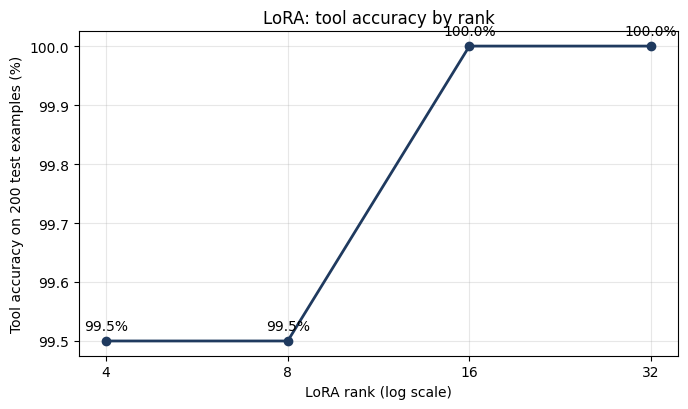

,rank,trainable_parameters,peak_train_memory_gb,train_minutes,json_valid,tool_accuracy,full_match
1,4,1089536,6.5394,11.2539,199,0.995,0.935
0,8,2179072,6.5508,11.2311,199,0.995,0.935
2,16,4358144,6.5759,11.2524,200,1.000,0.935
3,32,8716288,6.6246,11.2622,200,1.000,0.945


In [8]:
trained = main[main.method != "Baseline"]
best_row = trained.sort_values(["tool_accuracy", "full_match", "json_valid"], ascending=False).iloc[0]
BEST_METHOD = best_row.method
print("Best method:", BEST_METHOD)

rank_rows = [results[BEST_METHOD]] + [run(BEST_METHOD, r) for r in (4, 16, 32)]
ranks = pd.DataFrame(rank_rows).sort_values("rank")
BEST_RANK = int(ranks.sort_values(["tool_accuracy", "full_match", "json_valid"], ascending=False).iloc[0]["rank"])
print("Best overall run:", run_id(BEST_METHOD, BEST_RANK))
ranks.to_csv(WORK / "section3_rank_results.csv", index=False)
display_columns = ["rank", "trainable_parameters", "peak_train_memory_gb", "train_minutes", "json_valid", "tool_accuracy", "full_match"]

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(ranks["rank"], 100 * ranks.tool_accuracy, marker="o", color="#1F3A5F", linewidth=2)
for x, y in zip(ranks["rank"], 100 * ranks.tool_accuracy):
    ax.annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set_xscale("log", base=2)
ax.set_xticks(ranks["rank"], [str(int(r)) for r in ranks["rank"]])
ax.minorticks_off()
ax.set_xlabel("LoRA rank (log scale)")
ax.set_ylabel("Tool accuracy on 200 test examples (%)")
ax.set_title(f"{BEST_METHOD}: tool accuracy by rank")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(WORK / "section3_rank_plot.png", dpi=200)
plt.show()
ranks[display_columns].round(4)

## Section 4 evidence: adapter behaviour after merging
QLoRA merges into rounded 4-bit weights, while DoRA and plain LoRA merge into floating-point weights. This measures output agreement, speed, memory and no-call behaviour for the report's production decision, and includes the best run from Section 3. Merged outputs are saved so the differences can be read later.

In [9]:
merge_path = WORK / "merge_check.json"
sample = test_set[:50]

def measure(model, reference=None):
    if HAS_GPU:
        torch.cuda.reset_peak_memory_stats()
    out, speed = generate_all(model, sample)
    row = {"tokens_per_second": speed, "peak_memory_gb": peak_memory_gb(), "tool_accuracy": score_test(sample, out)[0]["tool_accuracy"]}
    no_call_out, _ = generate_all(model, no_call_test)
    row["no_call_false_calls_clean"] = score_no_call([o for e, o in zip(no_call_test, no_call_out) if e["user"] not in ANNOUNCED_IN_NO_CALL])
    if reference is not None:
        row["same_output_as_unmerged"] = sum(a == b for a, b in zip(out, reference)) / len(out)
    return row, out

if merge_path.exists():
    print(merge_path.read_text())
else:
    merge_rows, merge_outputs = [], {}
    targets = [("LoRA", 8), ("QLoRA", 8), ("DoRA", 8)]
    if (BEST_METHOD, BEST_RANK) not in targets:
        targets.append((BEST_METHOD, BEST_RANK))
    for method, rank in targets:
        if method == "QLoRA" and not HAS_GPU:
            continue
        name = run_id(method, rank)
        clear_memory()
        try:
            model = PeftModel.from_pretrained(load_base(quantized=method == "QLoRA"), WORK / "adapters" / name)
            row, attached = measure(model)
            saved = json.loads((WORK / f"{name}{'_smoke' if SMOKE else ''}_predictions.json").read_text(encoding="utf-8"))["test"]
            row["same_output_as_training_run"] = sum(a == b["output"] for a, b in zip(attached, saved)) / len(attached)
            merge_rows.append({"run": name, "state": "adapter attached", **row})
            model = model.merge_and_unload()
            row, merged = measure(model, attached)
            merge_rows.append({"run": name, "state": "merged", **row})
            merge_outputs[name] = {"attached": attached, "merged": merged}
            del model
        except Exception as error:   # a merge problem must not lose the finished training runs
            print(name, "merge check failed:", repr(error))
            merge_rows.append({"run": name, "state": "failed", "error": repr(error)})
    merge_path.write_text(json.dumps(merge_rows, indent=1))
    (WORK / "merge_outputs.json").write_text(json.dumps(merge_outputs, ensure_ascii=False, indent=1), encoding="utf-8")
    clear_memory()
    print(pd.DataFrame(merge_rows).round(3).to_string(index=False))

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/peft/tuners/lora/bnb.py:377: UserWarning: Merge lora module to 4-bit linear may get different generations due to rounding errors.
  warnings.warn(


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

     run            state  tokens_per_second  peak_memory_gb  tool_accuracy  no_call_false_calls_clean  same_output_as_training_run  same_output_as_unmerged
 LoRA_r8 adapter attached             72.251           3.159           1.00                          2                          1.0                      NaN
 LoRA_r8           merged            110.928           3.151           1.00                          2                          NaN                     1.00
QLoRA_r8 adapter attached             51.881           1.356           1.00                          2                          1.0                      NaN
QLoRA_r8           merged             64.710           1.348           0.86                          9                          NaN                     0.46
 DoRA_r8 adapter attached             40.579           3.162           1.00                          2                          1.0                      NaN
 DoRA_r8           merged            109.213           3.1

## Section 4 evidence: remaining failures of the best model

In [10]:
best_name = run_id(BEST_METHOD, BEST_RANK)
predictions = json.loads((WORK / f"{best_name}{'_smoke' if SMOKE else ''}_predictions.json").read_text(encoding="utf-8"))
print("Failures below are for", best_name)
failures = pd.DataFrame([p for p in predictions["test"] if p["error"]])
failures.to_csv(WORK / "best_model_failures.csv", index=False)
print("Failures on the 200-example test:", len(failures))
print(failures.error.value_counts() if len(failures) else "none")
company_results = pd.DataFrame(predictions["company"])
company_results.to_csv(WORK / "best_model_company_outputs.csv", index=False)
pd.set_option("display.max_colwidth", 140)
failures.head(15)[["user", "gold", "output", "error"]] if len(failures) else None

Failures below are for LoRA_r32
Failures on the 200-example test: 11
error
wrong_argument_value    8
missing_argument        2
extra_argument          1
Name: count, dtype: int64


,user,gold,output,error
0,"I have a sentence in French that I need translated to English. The sentence is ""Je suis très heureux de vous rencontrer"".","{""name"": ""translate_text"", ""arguments"": {""text"": ""Je suis très heureux de vous rencontrer"", ""source_language"": ""French"", ""target_languag...","{""name"": ""translate_text"", ""arguments"": {""text"": ""Je suis très heureux de vous rencontrer"", ""source_language"": ""fr"", ""target_language"": ...",wrong_argument_value
1,I'm in New York and I'm craving for some Italian food. Can you find me some good Italian restaurants nearby?,"{""name"": ""find_nearby_restaurants"", ""arguments"": {""location"": ""New York"", ""cuisine"": ""Italian"", ""max_results"": 5}}","{""name"": ""find_nearby_restaurants"", ""arguments"": {""location"": ""New York"", ""cuisine"": ""Italian""}}",missing_argument
2,"I need to schedule a meeting for tomorrow at 10 AM and it will end at 11 AM. The meeting is titled ""Project Discussion"" and it will be h...","{""name"": ""create_calendar_event"", ""arguments"": {""title"": ""Project Discussion"", ""start_time"": ""2022-03-15 10:00:00"", ""end_time"": ""2022-03...","{""name"": ""create_calendar_event"", ""arguments"": {""title"": ""Project Discussion"", ""start_time"": ""2022-04-15T10:00:00"", ""end_time"": ""2022-04...",wrong_argument_value
3,"Hi, I need to find a flight from New York to London on 15th of next month.","{""name"": ""search_flights"", ""arguments"": {""origin"": ""New York"", ""destination"": ""London"", ""date"": ""15th of next month""}}","{""name"": ""search_flights"", ""arguments"": {""origin"": ""New York"", ""destination"": ""London"", ""date"": ""2022-06-15""}}",wrong_argument_value
4,"Can you translate ""Bonjour, comment ça va?"" from French to English for me?","{""name"": ""translate_text"", ""arguments"": {""text"": ""Bonjour, comment ça va?"", ""from_language"": ""French"", ""to_language"": ""English""}}","{""name"": ""translate_text"", ""arguments"": {""text"": ""Bonjour, comment ça va?"", ""from_language"": ""fr"", ""to_language"": ""en""}}",wrong_argument_value
5,"Hi, I have a sentence in French that I need translated to English. The sentence is ""Je suis très heureux de vous rencontrer"".","{""name"": ""translate_text"", ""arguments"": {""text"": ""Je suis très heureux de vous rencontrer"", ""source_language"": ""French"", ""target_languag...","{""name"": ""translate_text"", ""arguments"": {""text"": ""Je suis très heureux de vous rencontrer"", ""source_language"": ""fr"", ""target_language"": ...",wrong_argument_value
6,I'm looking for a recipe for a vegetarian lasagna.,"{""name"": ""search_recipes"", ""arguments"": {""query"": ""vegetarian lasagna"", ""diet"": ""vegetarian""}}","{""name"": ""search_recipes"", ""arguments"": {""query"": ""vegetarian lasagna""}}",missing_argument
7,Can you get me the latest news headlines from the United States?,"{""name"": ""get_news_headlines"", ""arguments"": {""category"": ""general"", ""country"": ""US""}}","{""name"": ""get_news_headlines"", ""arguments"": {""category"": """", ""country"": ""United States""}}",wrong_argument_value
8,I need to book a flight to Paris for 2 people. We want to leave on 15th June and return on 30th June.,"{""name"": ""book_flight"", ""arguments"": {""destination"": ""Paris"", ""departure_date"": ""2022-06-15"", ""return_date"": ""2022-06-30"", ""passengers"":...","{""name"": ""book_flight"", ""arguments"": {""destination"": ""Paris"", ""departure_date"": ""15th June"", ""return_date"": ""30th June"", ""passengers"": 2}}",wrong_argument_value
9,I need to track my expenses. I just bought a new laptop for $1200 under the category of electronics.,"{""name"": ""track_expenses"", ""arguments"": {""expense_description"": ""New Laptop"", ""amount"": 1200, ""category"": ""Electronics""}}","{""name"": ""track_expenses"", ""arguments"": {""expense_description"": ""new laptop"", ""amount"": 1200, ""category"": ""electronics""}}",wrong_argument_value


## When finished
Choose *File > Download > Download .ipynb* to keep this notebook with its outputs, and rename it `Assignment_Beta_Question_no_2_23k-0078.ipynb` if needed. Then bring back the whole `MyDrive/assignment_beta_q2_fixed` folder.